<a href="https://colab.research.google.com/github/soumaya-lamrhari/customer-conversion-prediction/blob/main/notebooks/1_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Conversion Prediction

## Objective

In this project, I use customer and marketing campaign data to predict whether a customer will subscribe to a term deposit.

The main goal is to identify customers with a higher likelihood of conversion, so that marketing efforts can be focused on those most likely to convert.

## Business Question

Which customers are most likely to subscribe to a term deposit, and how can the bank use these predictions to prioritize customers for marketing outreach?


In [ ]:
!pip install -q ucimlrepo

In [ ]:
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

In [ ]:
# Load the Bank Marketing dataset from the UCI repository
bank_marketing = fetch_ucirepo(id=222)
# Separate features and target for modeling
X = bank_marketing.data.features
y = bank_marketing.data.targets

# Data Exploration

Before building the model, I first explore the dataset to understand its structure, check data quality, and examine the conversion outcome.

In [ ]:
# Check the size of the feature set and target before starting the analysis
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (45211, 16)
Target shape: (45211, 1)


In [ ]:
# Review the available variables before deciding how to prepare them for modeling
print("Feature columns:")
print(X.columns.tolist())

print("\nTarget column:")
print(y.columns.tolist())

Feature columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']

Target column:
['y']


In [ ]:
# Preview a few records to understand how customer and campaign information is represented
X.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN


In [ ]:
# Check data types to understand which features are numerical and categorical
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
dtypes: int64(7), object(9)
memory usage: 5.5+ MB


In [ ]:
# Quantify missing values before deciding how they should be handled
missing_values = pd.DataFrame({
    "missing_count": X.isnull().sum(),
    "missing_percentage": (X.isnull().mean() * 100).round(2)
})

missing_values[missing_values["missing_count"] > 0].sort_values(
    "missing_percentage", ascending=False
)

,missing_count,missing_percentage
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


In [ ]:
# Inspect categories in features with missing values before making any cleaning decision
for column in ["poutcome", "contact", "education", "job"]:
    print(f"\n{column}:")
    print(X[column].value_counts(dropna=False))


poutcome:
poutcome
NaN        36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

contact:
contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64

education:
education
secondary    23202
tertiary     13301
primary       6851
NaN           1857
Name: count, dtype: int64

job:
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
NaN               288
Name: count, dtype: int64


In [ ]:
# Check if missing previous-campaign outcomes are linked to customers
# who had no prior campaign contact
X.groupby(X["poutcome"].isna())[["previous", "pdays"]].agg(
    ["count", "mean", "median", "min", "max"]
)

previous                            pdays                            
            count      mean median min  max  count        mean median min  max
poutcome                                                                      
False        8252  3.177412    2.0   1  275   8252  224.544353  194.5   1  871
True        36959  0.000460    0.0   0    7  36959   -0.962039   -1.0  -1  528

In [ ]:
# Check how often poutcome is missing despite a recorded previous campaign contact
missing_poutcome_with_history = X[
    X["poutcome"].isna() & (X["previous"] > 0)
]

print("Missing poutcome with previous contact:",
      len(missing_poutcome_with_history))

print("Percentage of missing poutcome cases:",
      round(len(missing_poutcome_with_history) / X["poutcome"].isna().sum() * 100, 2),
      "%")

Missing poutcome with previous contact: 5
Percentage of missing poutcome cases: 0.01 %


**Observation:** Most missing values in `poutcome` are associated with customers who had no previous campaign contact. Only 5 customers with a missing `poutcome` had a recorded previous contact. This suggests that the missing values mainly represent the absence of a previous campaign outcome rather than a general data quality issue.

In [ ]:
# Check whether missing contact information is concentrated in specific campaign months
contact_missing_by_month = pd.crosstab(
    X["month"],
    X["contact"].isna(),
    normalize="index"
) * 100

contact_missing_by_month.columns = ["contact_available", "contact_missing"]

contact_missing_by_month.round(2)

,contact_available,contact_missing
month,,
apr,99.80,0.20
aug,99.18,0.82
dec,98.60,1.40
feb,99.51,0.49
jan,99.36,0.64
jul,96.00,4.00
jun,15.15,84.85
mar,98.53,1.47
may,42.07,57.93


**Observation:** Missing values in `contact` are mainly concentrated in May and June, with 57.93% and 84.85% missing, respectively. This suggests that the missingness may be related to the timing of the campaign. However, the dataset does not provide enough information to determine the exact reason.

In [ ]:
# Review the distribution of job and education, including missing values
for column in ["education", "job"]:
    print(f"\n{column}:")
    print(X[column].value_counts(dropna=False, normalize=True).mul(100).round(2))


education:
education
secondary    51.32
tertiary     29.42
primary      15.15
NaN           4.11
Name: proportion, dtype: float64

job:
job
blue-collar      21.53
management       20.92
technician       16.80
admin.           11.44
services          9.19
retired           5.01
self-employed     3.49
entrepreneur      3.29
unemployed        2.88
housemaid         2.74
student           2.07
NaN               0.64
Name: proportion, dtype: float64


**Observation:** Missing values are relatively low for `education` (4.11%) and `job` (0.64%). At this stage, there is no clear indication of why these values are missing, so I will decide how to handle them during preprocessing.

In [ ]:
# Check the distribution of the target to understand the conversion rate
target_distribution = y["y"].value_counts(normalize=True).mul(100).round(2)

target_distribution

,proportion
y,
no,88.3
yes,11.7


**Observation:** The target is imbalanced, with 11.7% of customers subscribing to the term deposit and 88.3% not subscribing. Because of this imbalance, accuracy alone may not be a reliable measure of model performance. I will consider metrics such as precision, recall, and PR-AUC when evaluating the model.

In [ ]:
# Check the number of converted and non-converted customers
y["y"].value_counts()

,count
y,
no,39922
yes,5289


In [ ]:
# Review numerical features to understand their ranges and identify unusual values
X.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day_of_week,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


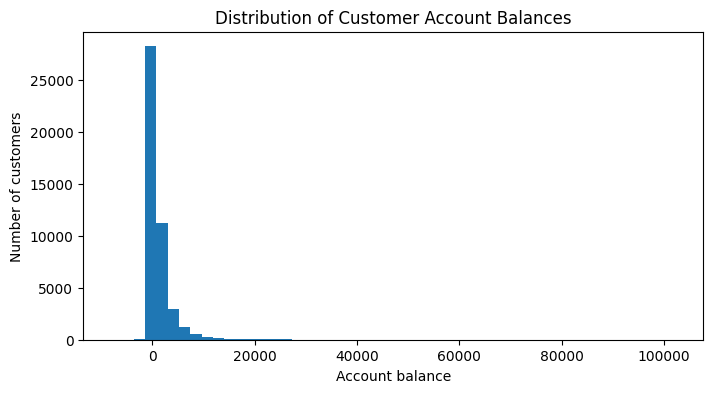

In [ ]:
import matplotlib.pyplot as plt

# Visualize account balances to understand their distribution and extreme values
plt.figure(figsize=(8, 4))
plt.hist(X["balance"], bins=50)
plt.xlabel("Account balance")
plt.ylabel("Number of customers")
plt.title("Distribution of Customer Account Balances")
plt.show()

**Observation:** Customer balance is strongly right-skewed. Most customers have relatively low balances, while a small number have much higher balances. These extreme values may represent valid customer accounts, so they will not be removed without further evidence that they are data errors.

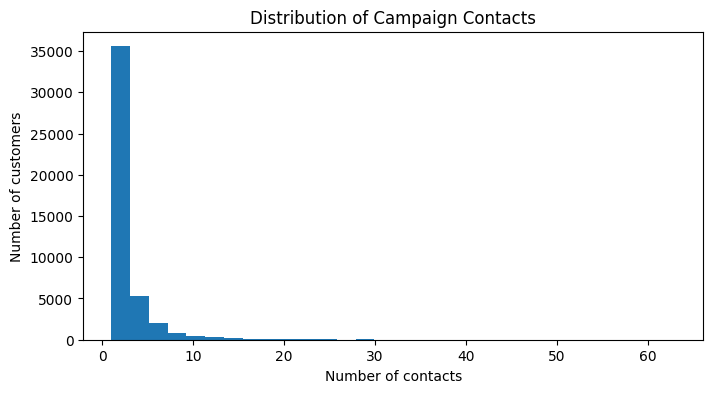

In [ ]:
# Examine how often customers were contacted during the current campaign
plt.figure(figsize=(8, 4))
plt.hist(X["campaign"], bins=30)
plt.xlabel("Number of contacts")
plt.ylabel("Number of customers")
plt.title("Distribution of Campaign Contacts")
plt.show()

**Observation:** The number of campaign contacts is strongly right-skewed. Most customers were contacted only a few times, while a small number were contacted many more times, with a maximum of 63 contacts.

In [ ]:
# Compare the number of campaign contacts by conversion outcome
data = X.copy()
data["y"] = y["y"]

data.groupby("y")["campaign"].mean()

,campaign
y,
no,2.846350
yes,2.141047


**Observation:** Customers who subscribed were contacted 2.14 times on average, compared with 2.85 times for customers who did not subscribe. This suggests that non-subscribers were contacted more often on average, although this does not necessarily mean that fewer contacts cause higher conversion.

In [ ]:
data.groupby("y")["campaign"].median()

,campaign
y,
no,2.0
yes,2.0


**Observation:** The median is 2 contacts for both groups. This shows that the typical number of contacts was similar for customers who subscribed and those who did not.

In [ ]:
# Compare account balances between subscribers and non-subscribers
data.groupby("y")["balance"].median()

,balance
y,
no,417.0
yes,733.0


**Observation:** Customers who subscribed had a higher median balance (€733) compared with customers who did not subscribe (€417). This suggests that account balance may be related to the likelihood of subscribing.

In [ ]:
# Compare the typical call duration between subscribers and non-subscribers
data.groupby("y")["duration"].median()

,duration
y,
no,164.0
yes,426.0


**Observation:** Customers who subscribed had a much longer median call duration (426 seconds) compared with customers who did not subscribe (164 seconds). However, call duration is only known after the contact has started, so it would not be available when deciding which customers to prioritize. To avoid data leakage, I will exclude `duration` from the predictive model.

In [ ]:
# Check how many customers were not contacted in a previous campaign
(X["pdays"] == -1).value_counts()

,count
pdays,
True,36954
False,8257


In [ ]:
# Identify whether the customer was contacted in a previous campaign
data["previously_contacted"] = data["pdays"] != -1

data.groupby("previously_contacted")["y"].value_counts(normalize=True)

previously_contacted  y  
False                 no     0.908427
                      yes    0.091573
True                  no     0.769287
                      yes    0.230713
Name: proportion, dtype: float64

**Observation:** Customers who had been contacted in a previous campaign had a higher conversion rate (23.07%) than customers who had not been contacted previously (9.16%). This suggests that previous campaign contact may be useful for predicting conversion.

In [ ]:
# Compare previous campaign contacts between subscribers and non-subscribers
data.groupby("y")["previous"].median()

,previous
y,
no,0.0
yes,0.0


**Observation:** The median number of previous campaign contacts is 0 for both subscribers and non-subscribers. This is expected because most customers had not been contacted in a previous campaign.

In [ ]:
# Compare the average number of previous contacts between the two groups
data.groupby("y")["previous"].mean()

,previous
y,
no,0.502154
yes,1.170354


**Observation:** Customers who subscribed had more previous campaign contacts on average (1.17) than customers who did not subscribe (0.50). However, most customers had no previous contacts, so this difference should be interpreted carefully.

In [ ]:
# Calculate the conversion rate for each job category
data.groupby("job")["y"].apply(lambda x: (x == "yes").mean()).sort_values(ascending=False)

,y
job,
student,0.286780
retired,0.227915
unemployed,0.155027
management,0.137556
admin.,0.122027
self-employed,0.118429
technician,0.110570
services,0.088830
housemaid,0.087903


**Observation:** Conversion rates vary across job categories. Students had the highest conversion rate (28.68%), followed by retired customers (22.79%), while blue-collar customers had the lowest rate (7.28%). This suggests that job type is associated with conversion rate.

In [ ]:
# Conversion rate by education
data.groupby("education")["y"].apply(lambda x: (x == "yes").mean()).sort_values(ascending=False)

,y
education,
tertiary,0.150064
secondary,0.105594
primary,0.086265


**Observation:** Conversion rates vary across education levels. Customers with tertiary education had the highest conversion rate (15.01%), followed by secondary (10.56%) and primary education (8.63%). This suggests that education level is associated with conversion rate.

In [ ]:
# Conversion rate by housing loan status
data.groupby("housing")["y"].apply(lambda x: (x == "yes").mean())

,y
housing,
no,0.167024
yes,0.077000


**Observation:** Customers without a housing loan had a higher conversion rate (16.70%) than customers with a housing loan (7.70%). This suggests that housing loan status is associated with conversion rate.

In [ ]:
# Conversion rate by personal loan status
data.groupby("loan")["y"].apply(lambda x: (x == "yes").mean())

,y
loan,
no,0.126557
yes,0.066814


**Observation:** Customers without a personal loan had a higher conversion rate (12.66%) than customers with a personal loan (6.68%). This suggests that personal loan status is associated with conversion rate.

In [ ]:
# Conversion rate by previous campaign outcome
data.groupby("poutcome")["y"].apply(lambda x: (x == "yes").mean()).sort_values(ascending=False)

,y
poutcome,
success,0.647253
other,0.166848
failure,0.126097


**Observation:** Customers with a successful previous campaign had a much higher conversion rate (64.73%) than those with a previous failure (12.61%) or another outcome (16.68%). This suggests that previous campaign outcome is strongly associated with current conversion.

In [ ]:
# Conversion rate by contact month
data.groupby("month")["y"].apply(lambda x: (x == "yes").mean()).sort_values(ascending=False)


,y
month,
mar,0.519916
dec,0.467290
sep,0.464594
oct,0.437669
apr,0.196794
feb,0.166478
aug,0.110133
jun,0.102228
nov,0.101511


In [ ]:
# Number of customers contacted in each month
data["month"].value_counts()

,count
month,
may,13766
jul,6895
aug,6247
jun,5341
nov,3970
apr,2932
feb,2649
jan,1403
oct,738


**Observation:** Conversion rates vary considerably across months. March had the highest conversion rate (51.99%), followed by December (46.73%), September (46.46%), and October (43.77%), while May had the lowest rate (6.72%). This suggests that the month of contact is associated with conversion rate.

However, some of the months with the highest conversion rates have relatively small numbers of customers. Therefore, these high conversion rates should be interpreted with caution.

In [ ]:
# Compare customer volume and conversion rate by month
month_summary = data.groupby("month")["y"].agg(
    customer_count="count",
    conversion_rate=lambda x: (x == "yes").mean()
)

month_summary.sort_values("conversion_rate", ascending=False)

,customer_count,conversion_rate
month,,
mar,477,0.519916
dec,214,0.467290
sep,579,0.464594
oct,738,0.437669
apr,2932,0.196794
feb,2649,0.166478
aug,6247,0.110133
jun,5341,0.102228
nov,3970,0.101511


In [ ]:
# Create age groups for easier comparison
data["age_group"] = pd.cut(
    data["age"],
    bins=[18, 30, 40, 50, 60, 100],
    labels=["18-30", "31-40", "41-50", "51-60", "60+"],
    include_lowest=True
)
data["age_group"].value_counts().sort_index()

,count
age_group,
18-30,7030
31-40,17687
41-50,11239
51-60,8067
60+,1188


In [ ]:
# Conversion rate by age group
data.groupby("age_group", observed=True)["y"].apply(
    lambda x: (x == "yes").mean()
)

,y
age_group,
18-30,0.162873
31-40,0.102448
41-50,0.090666
51-60,0.100533
60+,0.422559


**Observation:** Conversion rates differ across age groups. Customers aged 60+ had the highest conversion rate (42.26%), while customers aged 41–50 had the lowest rate (9.07%). This suggests that age is associated with conversion rate.

In [ ]:
# Conversion rate by marital status
data.groupby("marital")["y"].apply(lambda x: (x == "yes").mean()).sort_values(ascending=False)

,y
marital,
single,0.149492
divorced,0.119455
married,0.101235


**Observation:** Conversion rates vary across marital status. Single customers had the highest conversion rate (14.95%), followed by divorced customers (11.95%) and married customers (10.12%). This suggests that marital status is associated with conversion rate.

In [ ]:
# Conversion rate by credit default status
data.groupby("default")["y"].apply(lambda x: (x == "yes").mean()).sort_values(ascending=False)

,y
default,
no,0.117961
yes,0.063804


**Observation:** Customers who were not in credit default had a higher conversion rate (11.80%) than customers who were in default (6.38%). This suggests that credit default status is associated with conversion rate.

In [ ]:
# Conversion rate by contact method
data.groupby("contact")["y"].apply(lambda x: (x == "yes").mean()).sort_values(ascending=False)

,y
contact,
cellular,0.149189
telephone,0.134205


In [ ]:
# Compare conversion for known vs missing contact method
data["contact_missing"] = data["contact"].isna()

data.groupby("contact_missing")["y"].apply(
    lambda x: (x == "yes").mean())

,y
contact_missing,
False,0.147836
True,0.040707


**Observation:** Customers with a known contact method had a higher conversion rate (14.78%) than customers with a missing contact method (4.07%). Since missing contact values are also concentrated in certain months, the missingness may contain useful information for predicting conversion.

In [ ]:
# Check the values stored in day_of_week
sorted(data["day_of_week"].unique())

[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17),
 np.int64(18),
 np.int64(19),
 np.int64(20),
 np.int64(21),
 np.int64(22),
 np.int64(23),
 np.int64(24),
 np.int64(25),
 np.int64(26),
 np.int64(27),
 np.int64(28),
 np.int64(29),
 np.int64(30),
 np.int64(31)]

In [ ]:
# Group contact days into periods of the month
data["day_group"] = pd.cut(
    data["day_of_week"],
    bins=[0, 10, 20, 31],
    labels=["Beginning", "Middle", "End"]
)

data["day_group"].value_counts()

,count
day_group,
Middle,18389
Beginning,13725
End,13097


In [ ]:
# Conversion rate by period of the month
data.groupby("day_group", observed=True)["y"].apply(
    lambda x: (x == "yes").mean()
)

,y
day_group,
Beginning,0.126339
Middle,0.110066
End,0.116897


**Observation:** Conversion rates are relatively similar across periods of the month. Customers contacted during the first 10 days had a slightly higher conversion rate (12.63%) than those contacted in the middle (11.01%) or at the end of the month (11.69%).

In [ ]:
# Check for duplicate rows
full_data = pd.concat([X, y], axis=1)

full_data.duplicated().sum()

np.int64(0)

**Observation:** No duplicate rows were found in the dataset.

## Key Data Exploration Findings

- The target is imbalanced, with 11.7% of customers subscribing to the term deposit.
- Previous campaign history appears useful for predicting conversion. Customers contacted in a previous campaign had a higher conversion rate, and previous campaign outcome showed a strong relationship with conversion.
- Conversion rates also varied across customer characteristics such as age, job, education, housing loan, personal loan, and credit default status.
- Account balance was higher among customers who subscribed, while the number of contacts during the current campaign was slightly lower on average for subscribers.
- Missing values in `poutcome` mainly represent customers with no previous campaign contact, while missing `contact` values appear to contain useful information and should not simply be removed.
- `duration` showed a strong relationship with conversion, but it will be excluded from the predictive model because it is not available before contacting the customer and could cause data leakage.
- No duplicate rows were found.